# Phase 1 - problem framing, EDA, feature-set decision and the learning paradigm

**Question.** What do the data look like, which fields must be excluded because they leak the outcome, and should we use supervised or unsupervised learning?

**Brief and report.** Parts A, B and C. Report Sections 1–3 and 4.1. Everything here uses the training rows only.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

### 1. Exploratory data analysis
`eda()` in `src/eda.py` builds the data dictionary and runs every check the brief lists, on the training rows: descriptive statistics, correlation (Pearson for numbers, Cramér's V for categories), distributions, skewness, missing values, duplicates, IQR outliers, class balance, noise and inconsistencies. Each result is saved to `results/phase1_*.csv` and each chart to `reports/figures/`.

**How to read the table.** It is the data dictionary: one row per field, with its type, range, share missing and role (predictor, excluded or target).

In [2]:
from src.eda import eda
dictionary = eda()
display(dictionary)

Phase 1 | EDA: Training rows only: 69877. Tables in results/phase1_*.csv, figures fig_C_*.


,feature,type,meaning,range_or_categories,missing_pct,model_role
0,hotel,categorical,City hotel or resort hotel,City Hotel; Resort Hotel,0.000,predictor
1,is_canceled,numeric,"Target: 1 if the booking was cancelled, 0 othe...",0 to 1,0.000,target
2,lead_time,numeric,Days between entering the booking and the arri...,0 to 737,0.000,predictor
3,arrival_date_year,numeric,Year of arrival,2015 to 2017,0.000,predictor
4,arrival_date_month,categorical,Month of arrival,April; August; December; February; January; Ju...,0.000,predictor
5,arrival_date_week_number,numeric,Week number of arrival,1 to 53,0.000,predictor
6,arrival_date_day_of_month,numeric,Day of the month of arrival,1 to 31,0.000,predictor
7,stays_in_weekend_nights,numeric,Booked weekend nights (Saturday or Sunday),0 to 19,0.000,predictor
8,stays_in_week_nights,numeric,Booked week nights (Monday to Friday),0 to 50,0.000,predictor
9,adults,numeric,Number of adults,0 to 55,0.000,predictor


The next cell shows each data-quality table and the EDA figures. For each one, ask two questions: what does it show, and how could it hurt a model? Report Table 4 answers both for every check.

**results/phase1_missing.csv**

,feature,missing_cells,missing_pct
0,hotel,0,0.000
1,lead_time,0,0.000
2,arrival_date_year,0,0.000
3,arrival_date_month,0,0.000
4,arrival_date_week_number,0,0.000
5,arrival_date_day_of_month,0,0.000
6,stays_in_weekend_nights,0,0.000
7,stays_in_week_nights,0,0.000
8,adults,0,0.000
9,children,3,0.004


**results/phase1_duplicates.csv**

,check,rows
0,exact duplicate source records removed (Phase 0),31994
1,training rows identical to another on all book...,11267
2,exact duplicates left in cleaned training rows,1623


**results/phase1_outliers.csv**

,feature,q1,q3,iqr_flagged_rows,flagged_pct
0,arrival_date_year,2016.00,2017.0,0,0.000
1,arrival_date_week_number,16.00,37.0,0,0.000
2,arrival_date_day_of_month,8.00,24.0,0,0.000
3,stays_in_weekend_nights,0.00,2.0,173,0.248
4,babies,0.00,0.0,729,1.043
5,stays_in_week_nights,1.00,4.0,1207,1.727
6,previous_cancellations,0.00,0.0,1324,1.895
7,lead_time,11.00,125.0,1889,2.703
8,adr,72.25,134.1,1984,2.839
9,total_of_special_requests,0.00,1.0,2151,3.078


... (7 outputs left out)

,feature,skew
0,arrival_date_year,-0.299
1,arrival_date_day_of_month,-0.002
2,arrival_date_week_number,0.022
3,total_of_special_requests,1.075
4,stays_in_weekend_nights,1.396
5,lead_time,1.436
6,stays_in_week_nights,2.692
7,children,3.492
8,required_car_parking_spaces,3.583
9,is_repeated_guest,4.767


**results/phase1_target_associations.csv**

,feature,cramers_v_to_target
0,reserved_room_type,0.057
1,meal,0.058
2,hotel,0.073
3,arrival_date_month,0.083
4,company,0.115
5,customer_type,0.130
6,distribution_channel,0.152
7,deposit_type,0.165
8,country,0.199
9,market_segment,0.221


**reports/figures/fig_C_01_correlations.png**

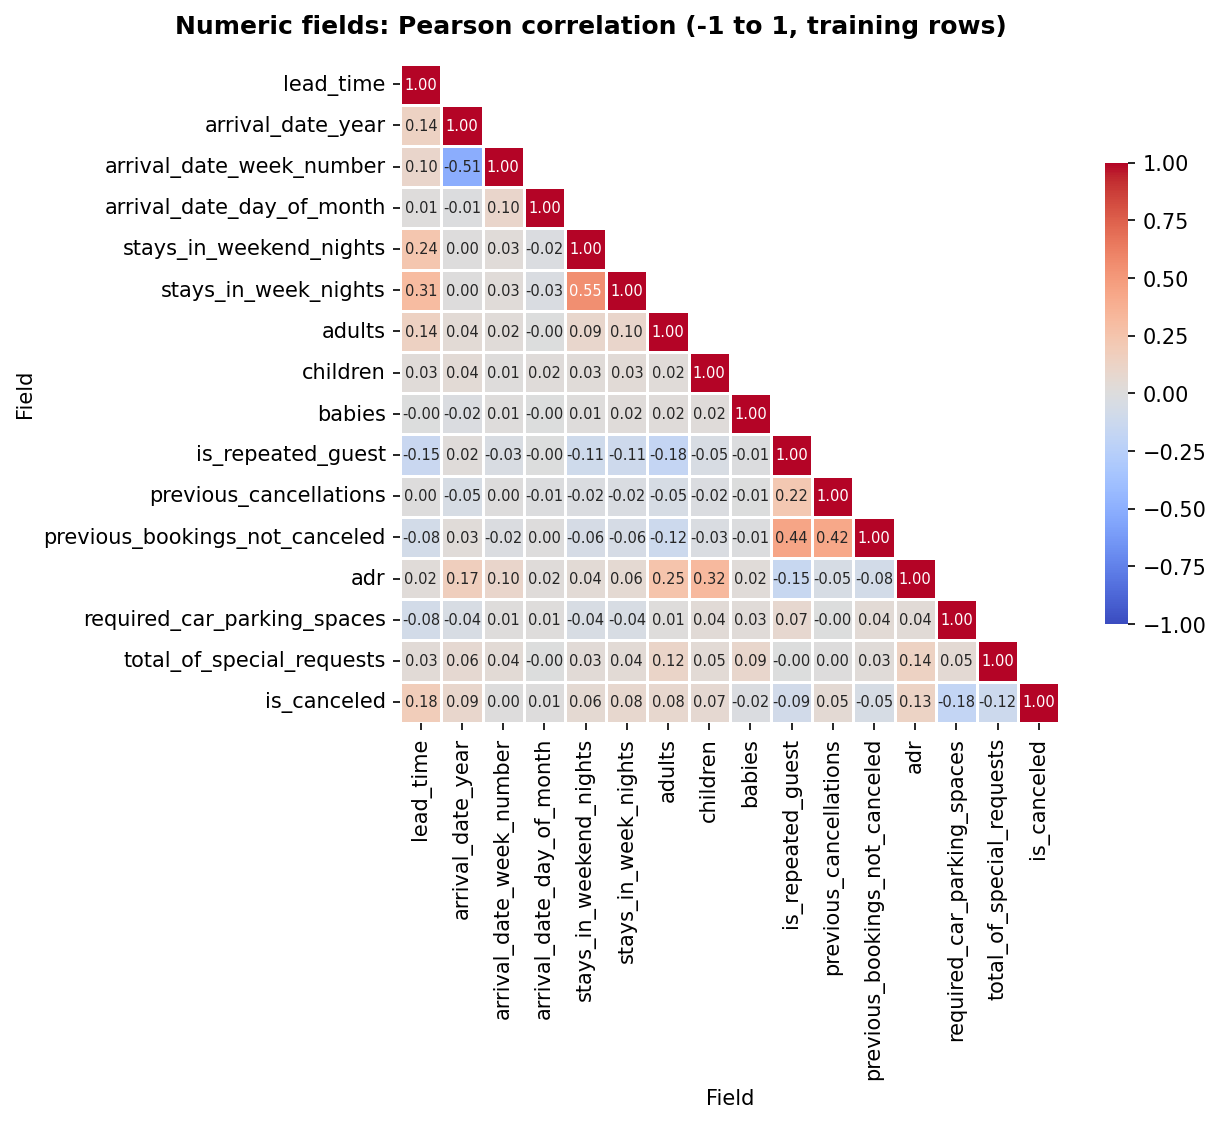

**reports/figures/fig_C_02_associations.png**

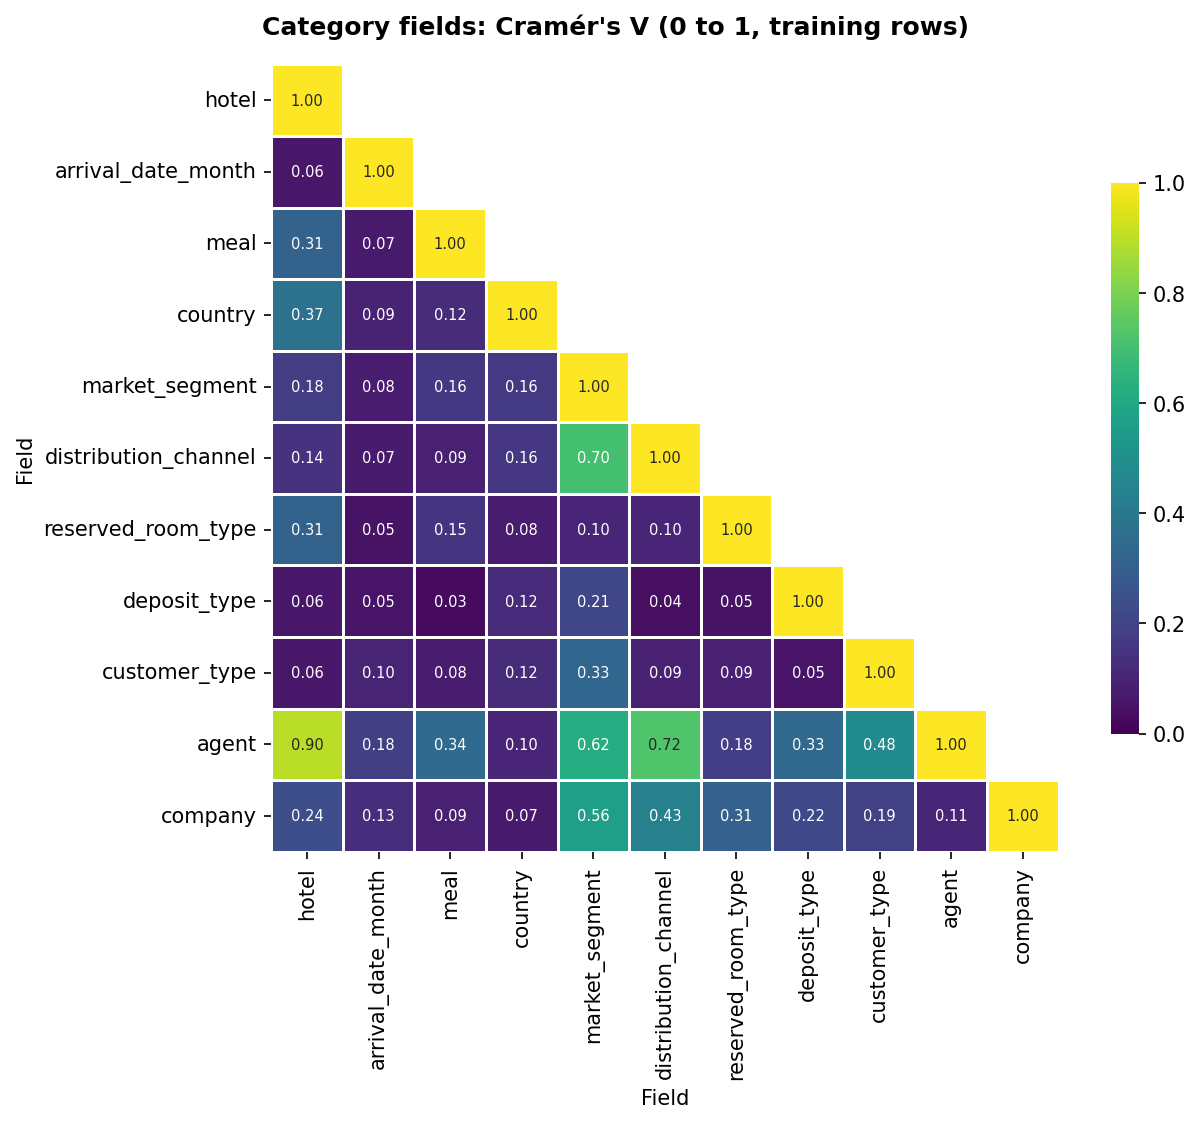

**reports/figures/fig_C_03_target_association.png**

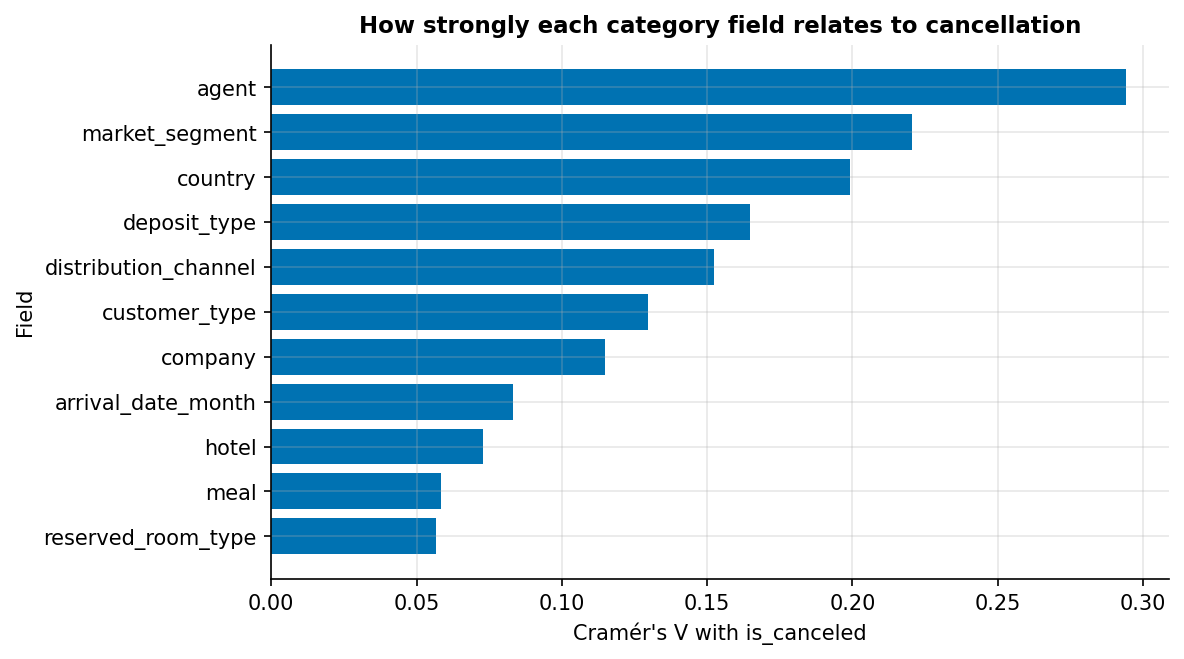

**reports/figures/fig_C_04_cancellation_rates.png**

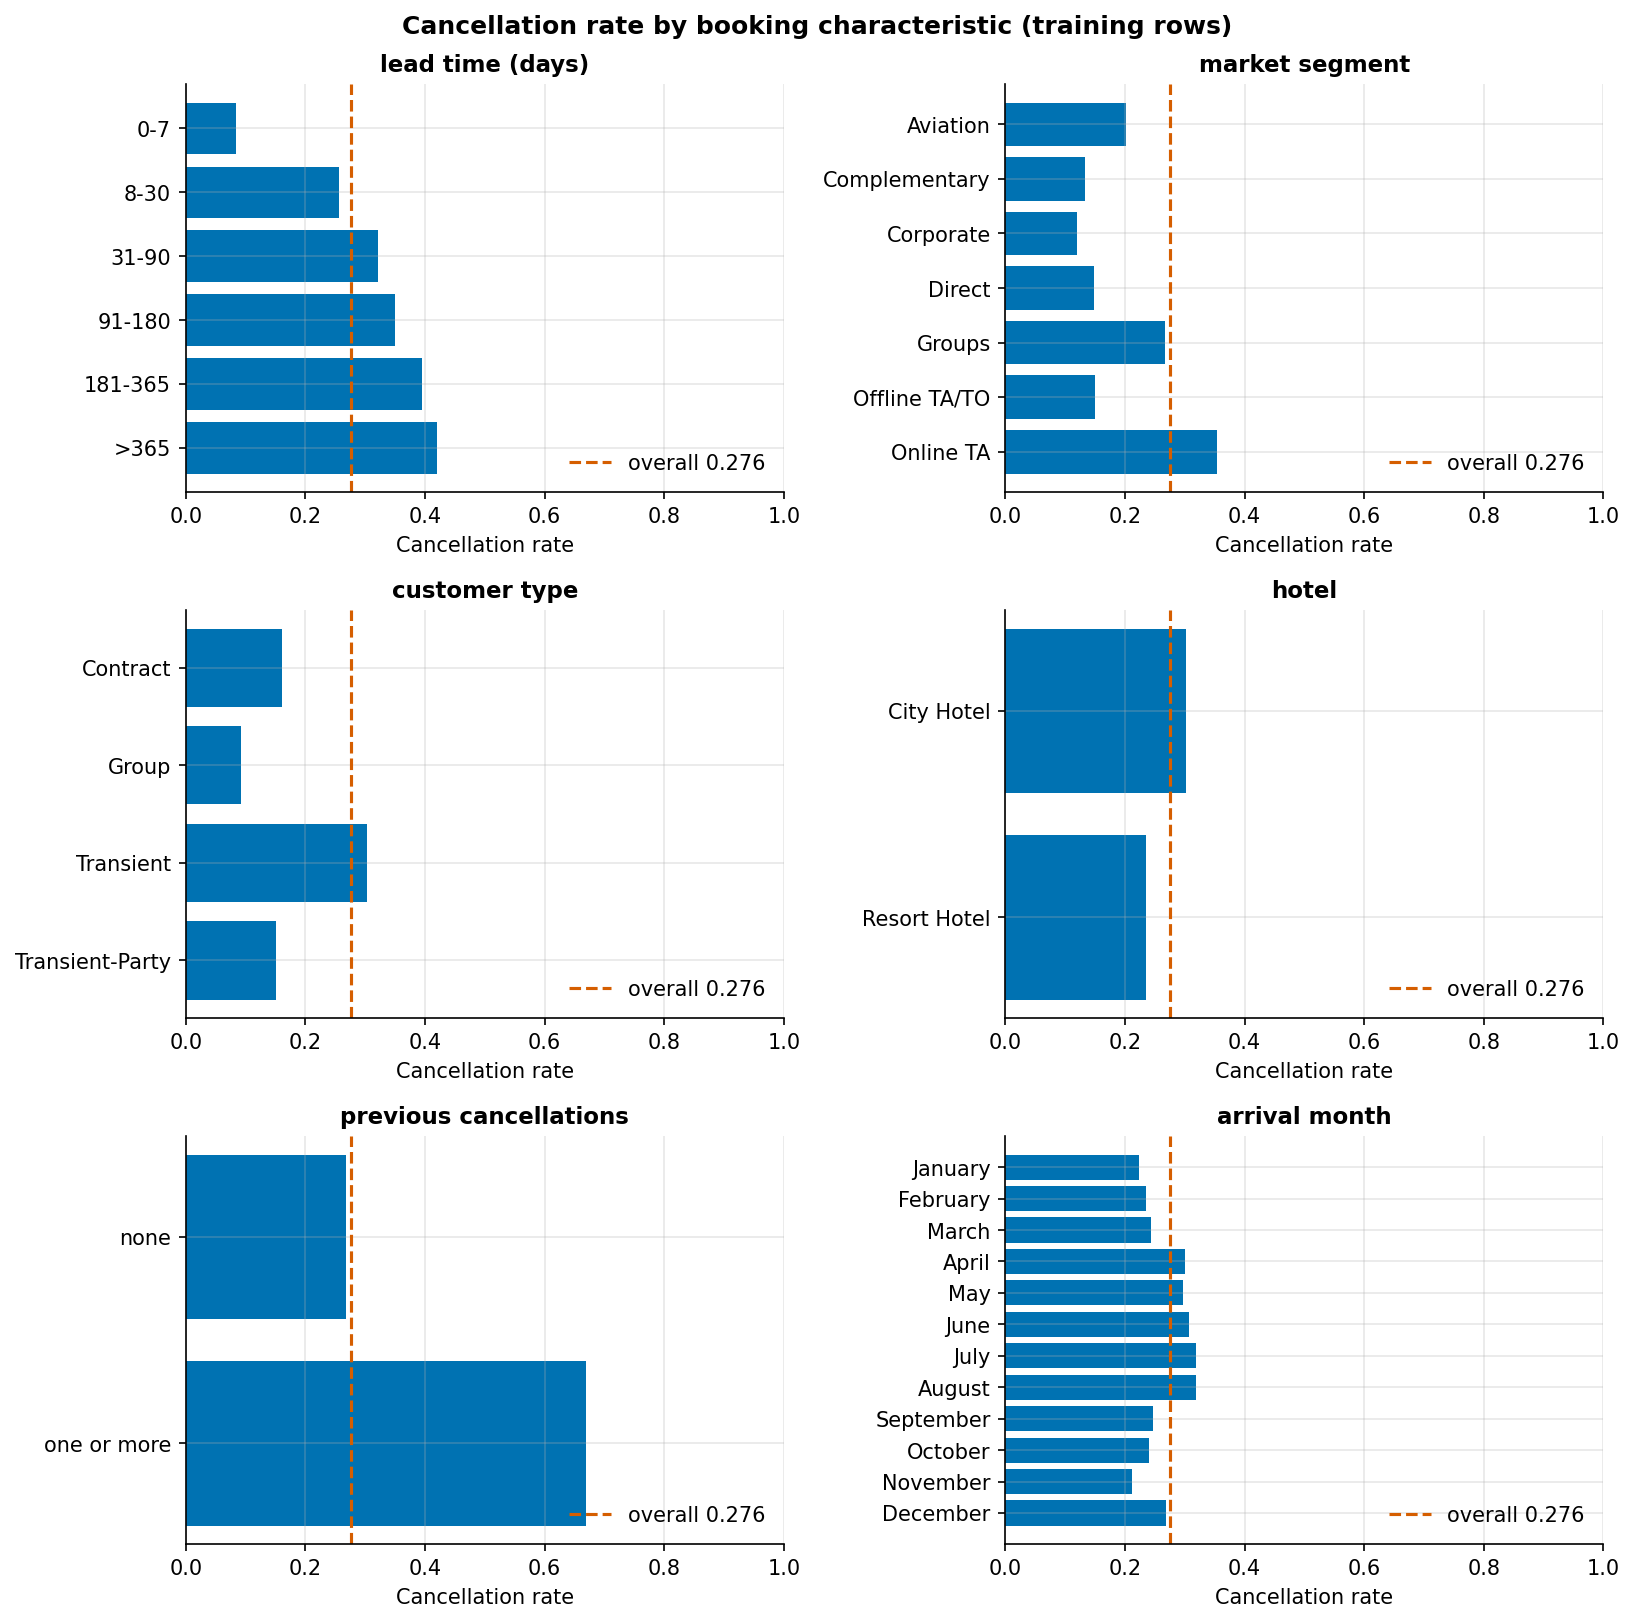

**reports/figures/fig_C_05_distributions.png**

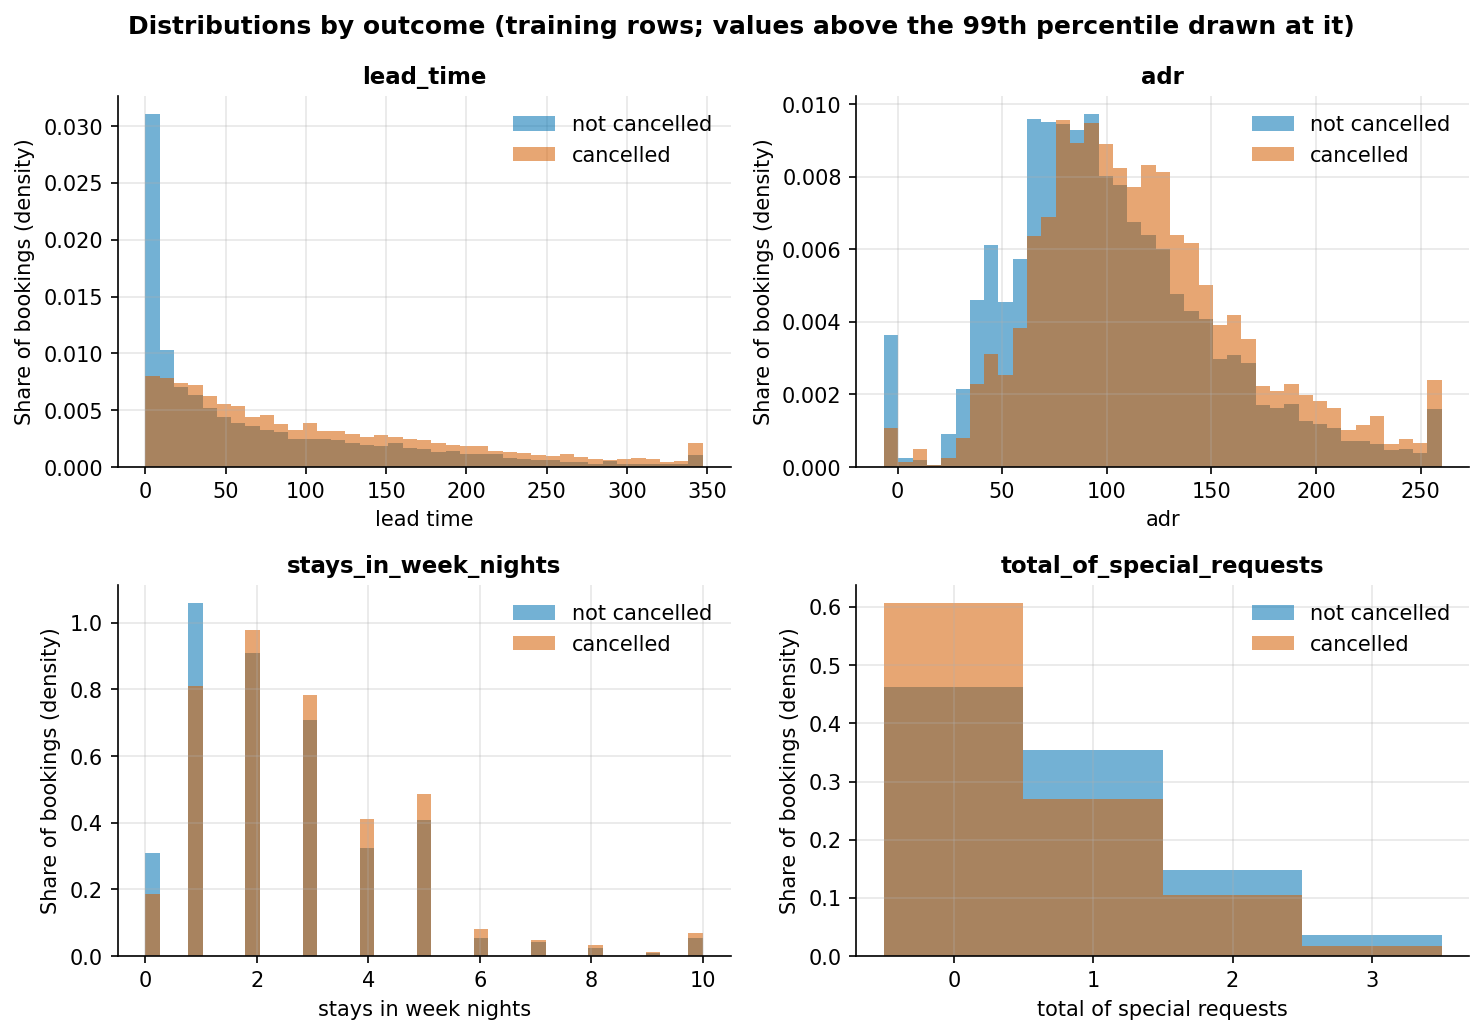

**reports/figures/fig_C_06_skewness.png**

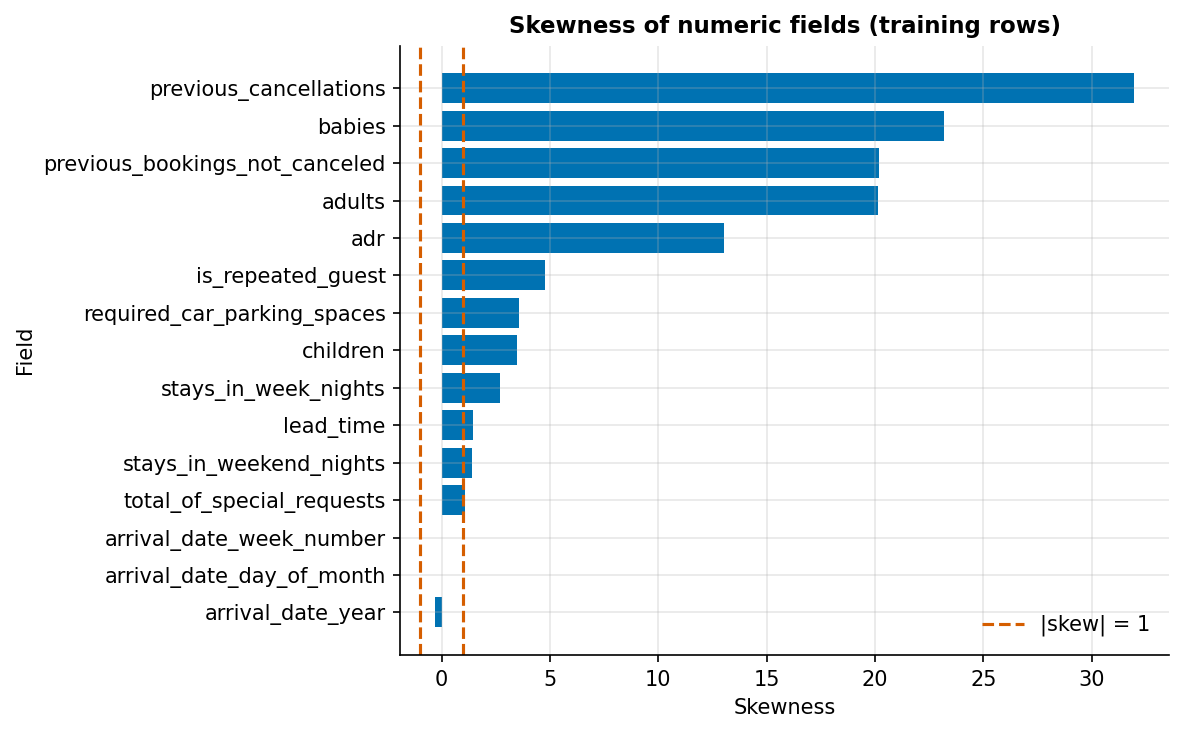

**reports/figures/fig_C_07_missing_values.png**

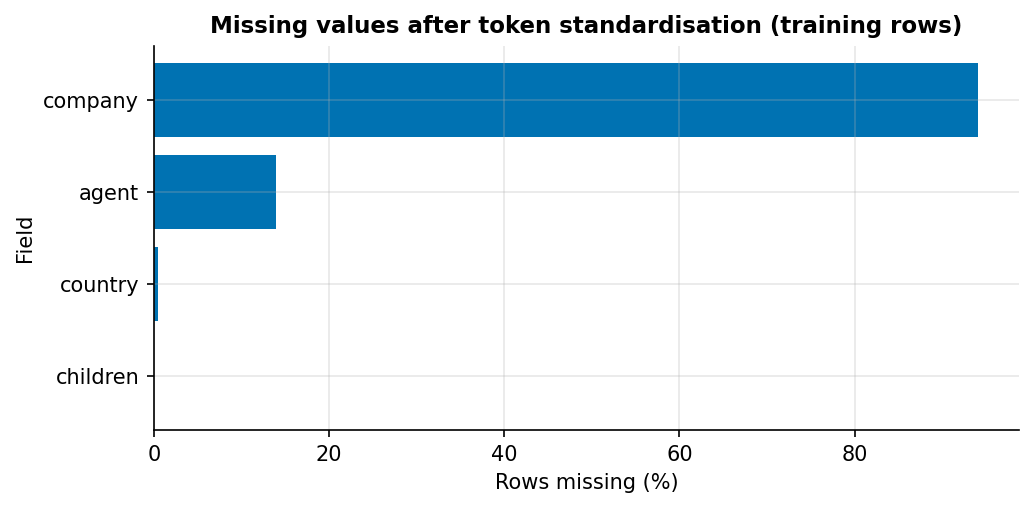

**reports/figures/fig_C_08_duplicates.png**

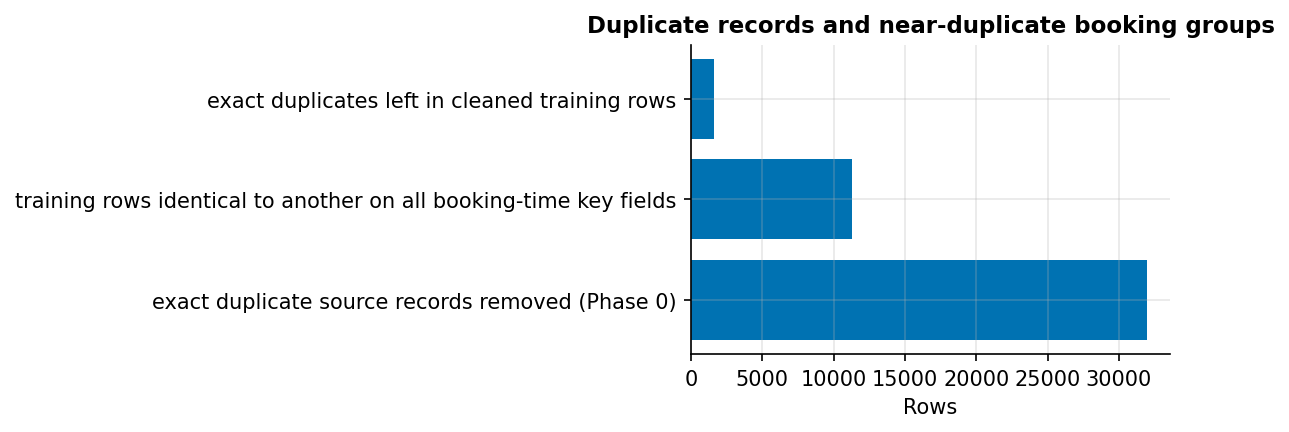

**reports/figures/fig_C_09_outliers.png**

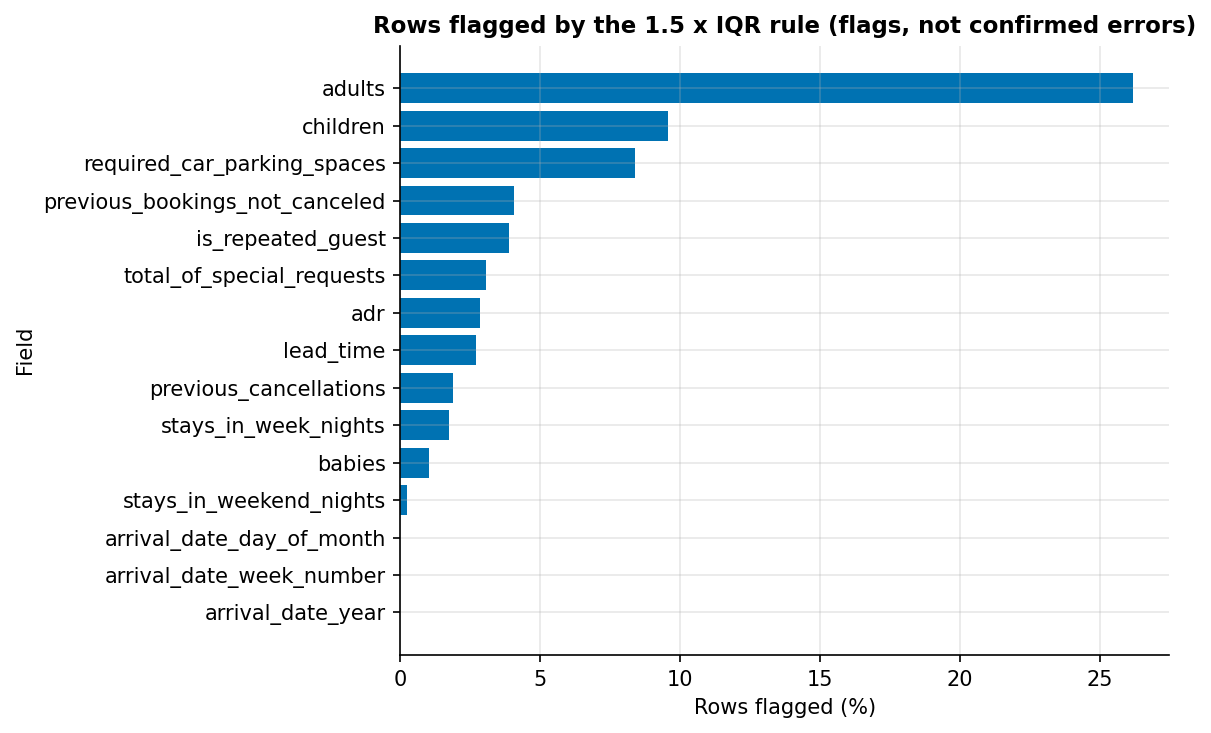

**reports/figures/fig_C_10_class_imbalance.png**

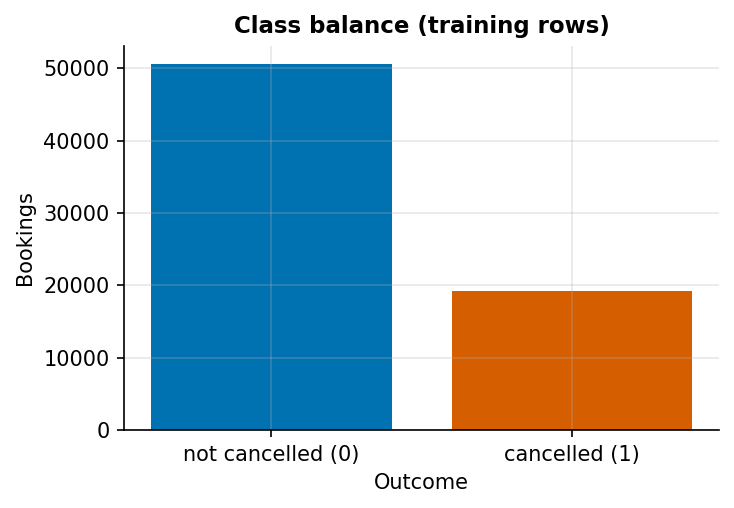

**reports/figures/fig_C_11_noise.png**

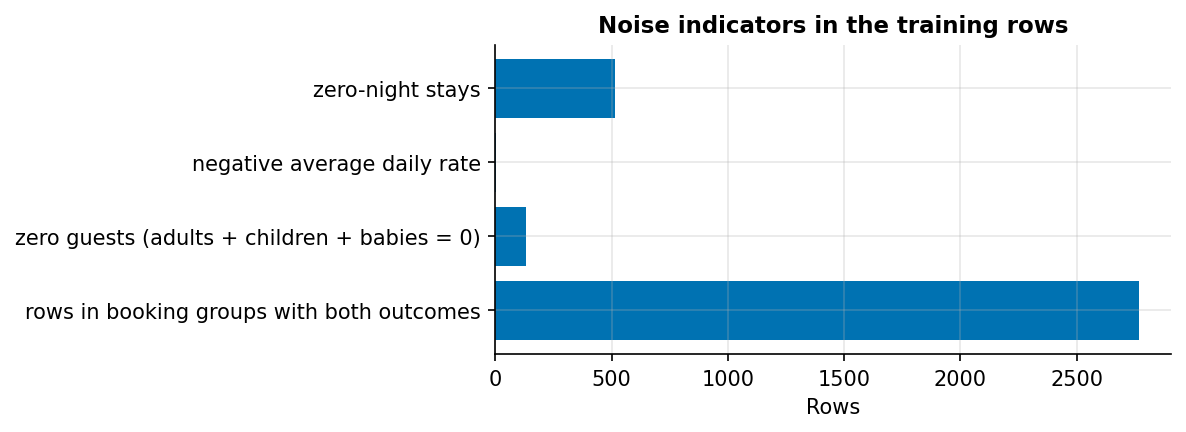

**reports/figures/fig_C_12_inconsistencies.png**

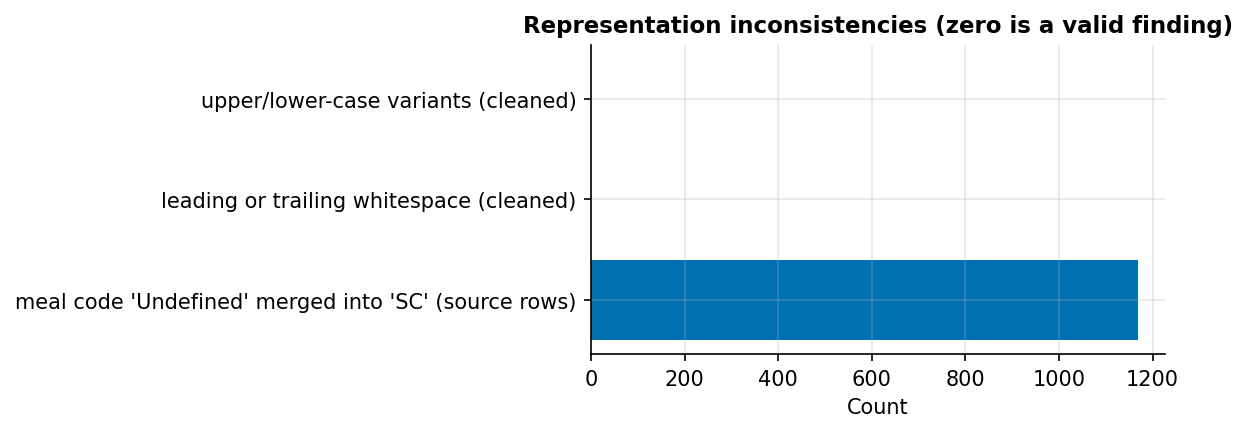

In [3]:
for name in ['phase1_missing.csv', 'phase1_duplicates.csv', 'phase1_outliers.csv', 'phase1_class_balance.csv', 'phase1_noise.csv', 'phase1_inconsistency_summary.csv', 'phase1_skewness.csv', 'phase1_target_associations.csv']:
    display(Markdown(f'**results/{name}**'))
    display(results(name))
show('fig_C_01_correlations.png', 'fig_C_02_associations.png', 'fig_C_03_target_association.png', 'fig_C_04_cancellation_rates.png', 'fig_C_05_distributions.png', 'fig_C_06_skewness.png', 'fig_C_07_missing_values.png', 'fig_C_08_duplicates.png', 'fig_C_09_outliers.png', 'fig_C_10_class_imbalance.png', 'fig_C_11_noise.png', 'fig_C_12_inconsistencies.png')

### 2. Leakage signals and the written exclusion rule
`leakage_signals()` in `src/features.py` computes the cancellation rate for each value of the six candidate fields. `decide_feature_set()` then applies the rule written before any model comparison (report Section 4.1). A field is excluded if (a) the dataset paper places it at or after the outcome, (b) a group of at least 500 training bookings cancels below 1% or above 99%, or (c) it is a calendar year.

**How to read the output.** `decisions` lists each candidate and the rule it met. A group that almost never or almost always cancels is the warning sign.

Phase 1 | feature set: Excluded ['country', 'required_car_parking_spaces', 'deposit_type', 'arrival_date_year']; kept candidates ['total_of_special_requests', 'adr'].


,feature,group,rows,cancel_rate
0,required_car_parking_spaces,none,64007,0.301
1,required_car_parking_spaces,one or more,5870,0.000
2,deposit_type,No Deposit,68961,0.268
3,deposit_type,Non Refund,825,0.950
4,deposit_type,Refundable,91,0.242
5,country,DEU,4280,0.195
6,country,ESP,5830,0.258
7,country,FRA,7043,0.199
8,country,GBR,8336,0.189
9,country,Other,22402,0.274


,feature,concern,rule,excluded,evidence
0,country,The dataset paper states that nationality is o...,a,True,"Antonio et al. (2019b, p. 45): hotels often do..."
1,required_car_parking_spaces,Parking is requested for the stay itself; chec...,b,True,"'one or more' (5,870 training rows) cancels at..."
2,deposit_type,The dataset paper derives it from payments mad...,a,True,"Antonio et al. (2019b, Table 1): calculated fr..."
3,total_of_special_requests,Requests can be added at any time up to arrival.,,False,No documented timing and no outcome-tied group...
4,adr,The average daily rate can be revised after bo...,,False,No documented timing and no outcome-tied group...
5,arrival_date_year,A calendar year cannot be learned for future y...,c,True,Each year occurs once; a future booking always...


**reports/figures/fig_A_02_leakage_signals.png**

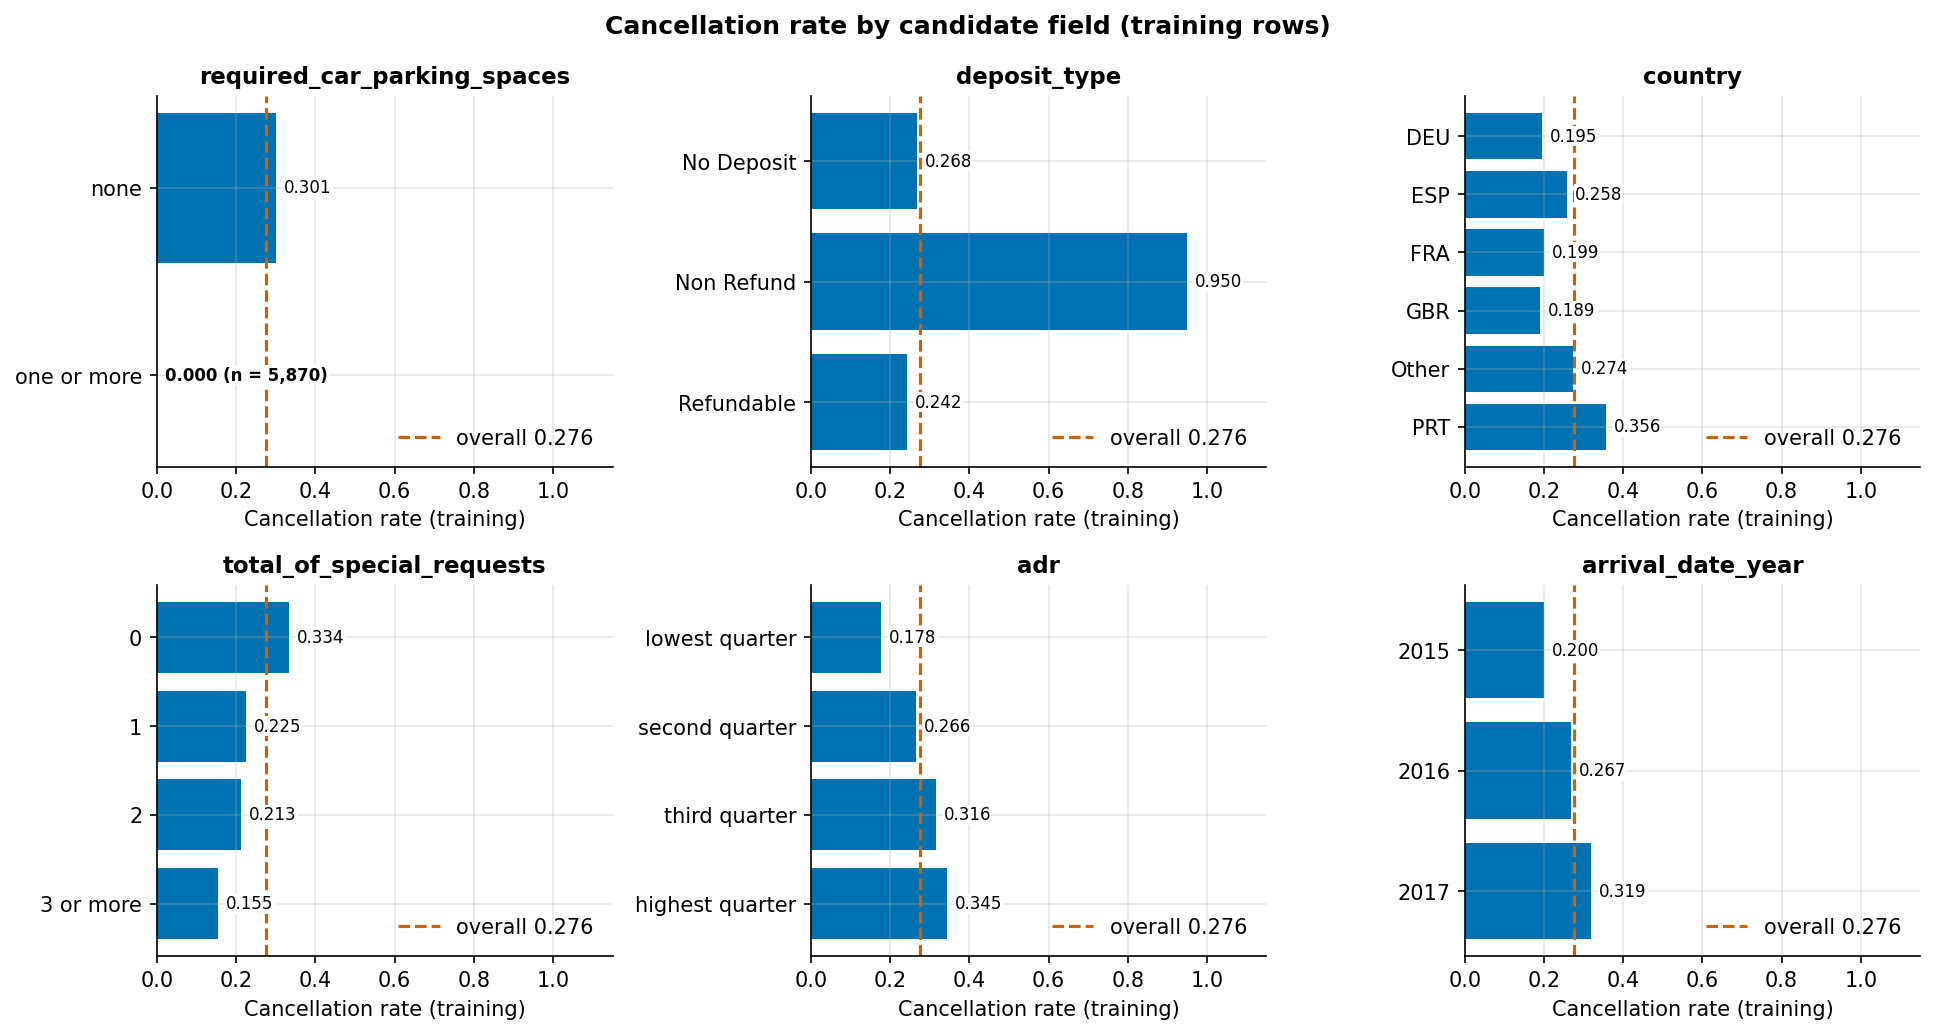

In [4]:
from src.features import decide_feature_set, feature_set_experiment, leakage_signals
signals = leakage_signals()
decisions = decide_feature_set(signals)
display(signals)
display(decisions)
show('fig_A_02_leakage_signals.png')

### 3. What each exclusion costs
`feature_set_experiment()` removes the candidate fields one at a time and scores logistic regression and gradient boosting with five group-aware CV folds.

**How to read the output.** AP falls as leaky fields are removed. The higher score is not the better model, because it relies on information that is not available when a booking is made (report Figure 1).

Phase 1 | feature-set CV: Logistic Regression, all candidates kept: AP 0.689


Phase 1 | feature-set CV: Logistic Regression, minus year: AP 0.687


Phase 1 | feature-set CV: Logistic Regression, minus year, parking: AP 0.660


Phase 1 | feature-set CV: Logistic Regression, minus year, parking, deposit: AP 0.649


Phase 1 | feature-set CV: Logistic Regression, selected set: AP 0.628


Phase 1 | feature-set CV: Logistic Regression, selected minus requests: AP 0.557


... (9 outputs left out)

Phase 1 | feature-set CV: Hist Gradient Boosting, all six candidates removed: AP 0.597


,model,feature_set,excluded,n_predictors,pr_auc_mean,pr_auc_std,f1_mean
0,Logistic Regression,all candidates kept,none,26,0.689,0.005,0.582
1,Logistic Regression,minus year,arrival_date_year,25,0.687,0.005,0.582
2,Logistic Regression,"minus year, parking",arrival_date_year; required_car_parking_spaces,24,0.660,0.004,0.544
3,Logistic Regression,"minus year, parking, deposit",arrival_date_year; required_car_parking_spaces...,23,0.649,0.003,0.543
4,Logistic Regression,selected set,country; required_car_parking_spaces; deposit_...,22,0.628,0.005,0.522
5,Logistic Regression,selected minus requests,country; required_car_parking_spaces; deposit_...,21,0.557,0.005,0.353
6,Logistic Regression,selected minus ADR,country; required_car_parking_spaces; deposit_...,21,0.625,0.005,0.518
7,Logistic Regression,all six candidates removed,country; required_car_parking_spaces; deposit_...,20,0.556,0.005,0.348
8,Hist Gradient Boosting,all candidates kept,none,26,0.792,0.007,0.697
9,Hist Gradient Boosting,minus year,arrival_date_year,25,0.776,0.006,0.680


,model,option,reference,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,p_holm
0,Hist Gradient Boosting,all candidates kept,selected set,0.116,3.316e-03,0.110,0.122,8.058e-07,5,0.25,1.048e-05
1,Hist Gradient Boosting,minus year,selected set,0.100,4.304e-03,0.092,0.108,4.122e-06,5,0.25,4.534e-05
2,Hist Gradient Boosting,"minus year, parking",selected set,0.077,2.734e-03,0.072,0.082,1.885e-06,5,0.25,2.262e-05
3,Hist Gradient Boosting,"minus year, parking, deposit",selected set,0.073,3.157e-03,0.067,0.078,4.317e-06,5,0.25,4.534e-05
4,Hist Gradient Boosting,selected minus requests,selected set,-0.074,1.862e-03,-0.078,-0.071,4.760e-07,5,0.25,6.664e-06
5,Hist Gradient Boosting,selected minus ADR,selected set,-0.004,9.508e-04,-0.006,-0.002,3.284e-03,5,0.25,6.568e-03
6,Hist Gradient Boosting,all six candidates removed,selected set,-0.079,4.103e-03,-0.087,-0.071,8.755e-06,5,0.25,7.004e-05
7,Logistic Regression,all candidates kept,selected set,0.061,5.021e-03,0.051,0.070,5.573e-05,5,0.25,2.810e-04
8,Logistic Regression,minus year,selected set,0.059,4.761e-03,0.050,0.068,5.119e-05,5,0.25,2.810e-04
9,Logistic Regression,"minus year, parking",selected set,0.032,2.524e-03,0.027,0.037,4.683e-05,5,0.25,2.810e-04


**reports/figures/fig_A_03_feature_set_cv.png**

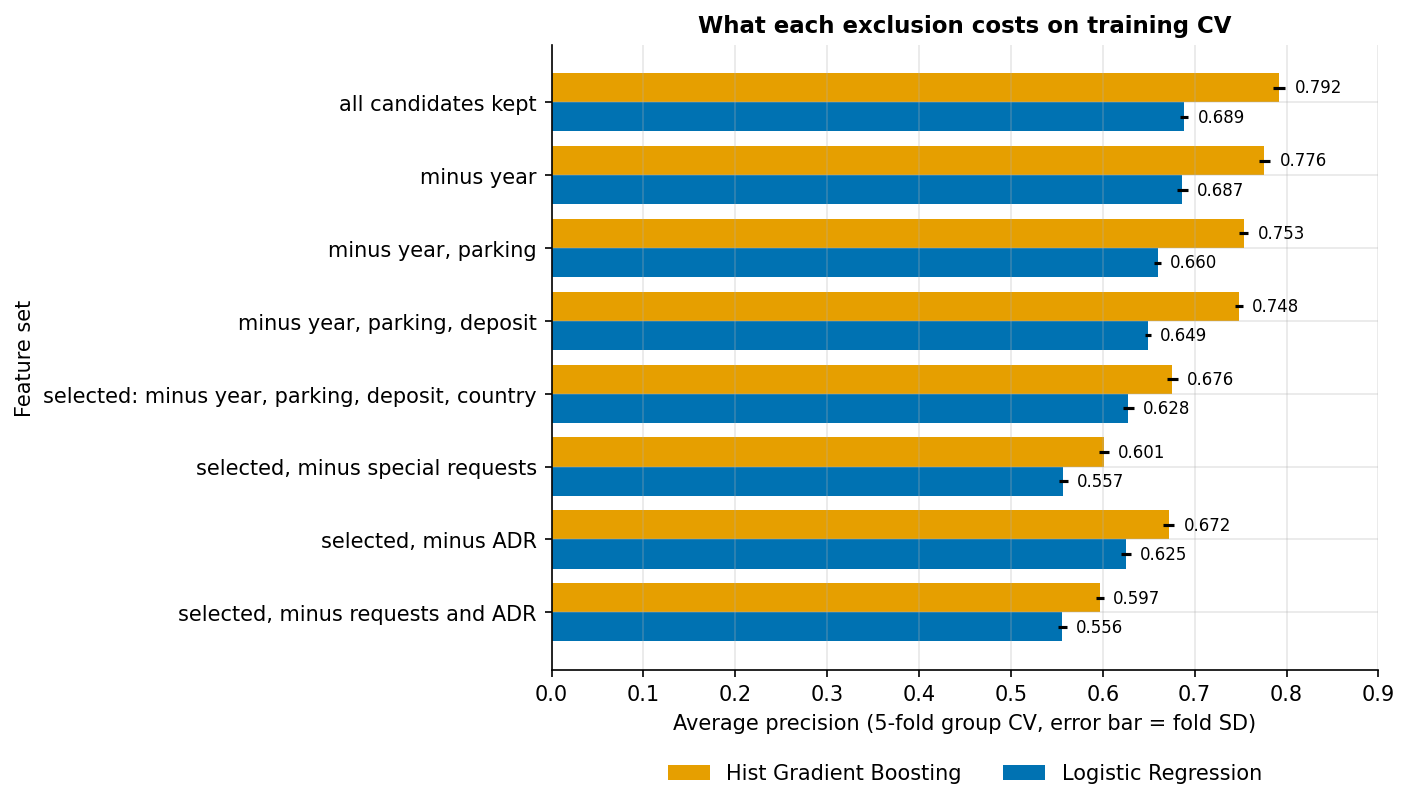

In [5]:
summary, comparison = feature_set_experiment()
display(summary[['model', 'feature_set', 'excluded', 'n_predictors', 'pr_auc_mean', 'pr_auc_std', 'f1_mean']])
display(comparison)
show('fig_A_03_feature_set_cv.png')